# Phase 4: Robustness, Validation and Model Diagnostics

## Objective
Phase 3 tested the FF-5 model with one set of construction choices: 2×3 factor sorts, June formation, Nifty 500 median size breakpoint, and financials excluded from RMW only. This phase checks whether the Phase 3 conclusions still hold when those choices change, when the sample is split, and when the factors are compared with an independent source, as Fama & French (2015) do before trusting any result.

## Questions this phase answers
1. Are the factors built correctly? (comparison with an external Indian factor library)
2. Do the factor premia survive other reasonable construction choices?
3. Is HML still redundant once the construction changes?
4. Does the model price portfolios it was **not** built on (industries, anomalies)?
5. Does FF-5 beat FF-3 and Carhart, and how much does adding momentum (FF-6) change?
6. Are the results stable over time, and do they depend on the Covid months?
7. Do the conclusions survive non-normal residuals (bootstrap GRS)?

## Inputs
- **Phase 2:** `phase_2_ff5_factors.csv`, `phase_2_monthly_panel_clean.csv`, `phase_2_formation.csv`, `characteristics_annual.csv`
- **Phase 3 (baseline):** factor summary, spanning regressions, test portfolios, portfolio summary, regression results, intercept summary, model comparison

## Steps
0. **Setup:** load all inputs and check they match what Phase 3 used.
1. **Freeze the baseline:** one reference table of Phase 3 FF-5 results (GRS, p-value, A|a|, A|a|/A|r̄|, average R², number of significant intercepts).
2. **External validation:** correlate our factors with the IIMA Indian factor library.
3. **Alternative factor constructions:** 2×2 sorts; financials excluded from all factors; Sept formation instead of June; large-cap size breakpoint; equal-weighted (diagnostic only).
4. **Spanning tests** under each alternative construction.
5. **Alternative test portfolios:** industry portfolios and anomaly portfolios (momentum, low volatility).
6. **Model comparison:** CAPM, FF-3, Carhart, FF-5, FF-6.
7. **Time stability:** two halves (Jul-2016 to Jun-2021, Jul-2021 to Jun-2026), 60-month rolling regressions, with and without Covid months.
8. **Statistical robustness:** residual normality tests and bootstrap GRS p-values.
9. **Verdict:** each test marked Pass / Fragile / Fail.

## Rules (classical FF-5)
- **FF-5 stays the main model.** Momentum (UMD) is not part of FF-5. It is used only in Carhart and FF-6 as a comparison and is reported as a known gap.
- **Value-weighted factors and portfolios** are the baseline. Equal-weighting is a diagnostic only.
- **Change one choice at a time** so every difference can be traced to its cause.
- **Pass / Fragile / Fail rules are fixed before any results are seen,** so they cannot be bent to fit the numbers.

## Outputs
- **Tables:** `phase_4_*.csv` plus one combined `phase_4_results.xlsx`
- **Plots:** saved in `plots/phase_4/`

## Limitations
- 120 months: tests have low power, and each half has only 60 months.
- Many regressions are run in this phase, so a few significant intercepts are expected by chance. No single result is called a finding.
- Thin portfolios (BM_S1_C1) remain flagged.

## Next
**Phase 5** uses only the parts of the model that pass here: attribution of stocks and funds, alpha screening, and the final report.

In [1]:
# ==========================================================
# STEP 0: Imports, Settings and Paths
# ==========================================================

import pandas as pd
import numpy as np
from pathlib import Path

import statsmodels.api as sm        # OLS regressions with Newey-West errors
from scipy import stats             # F, chi-square and normality tests
import matplotlib.pyplot as plt     # all plots
import seaborn as sns               # heatmaps

PROJECT_ROOT = Path().resolve().parent

# Methodology constants (must match Phases 2 and 3)
BP_LOW = 0.30       # low breakpoint (30th percentile)
BP_HIGH = 0.70      # high breakpoint (70th percentile)
FORM_MONTH = 6      # June snapshot
MIN_STOCKS = 5      # min stocks per portfolio-month (documented deviation)
NW_LAGS = 6         # Newey-West lags for monthly data

FACTOR_COLS = ["MKT", "SMB", "HML", "RMW", "CMA"]
MODELS = {                                  # same as Phase 3
    "CAPM": ["MKT"],
    "FF3":  ["MKT", "SMB", "HML"],
    "FF5":  ["MKT", "SMB", "HML", "RMW", "CMA"],
}                                           # Carhart and FF6 are added in Step 6, after UMD is built

FIRST_FORMATION = "2016-06-30"              # same formation years as Phase 3
LAST_FORMATION = "2025-06-30"
FLAGGED_PORTFOLIOS = ["BM_S1_C1"]           # thin portfolio found in Phase 3

# Phase 4 constants
SPLIT_DATE = "2021-06-30"       # last month of the first half (60 + 60 months)
COVID_START = "2020-03-31"      # Covid months, for the with/without check
COVID_END = "2020-12-31"
ROLL_WINDOW = 60                # months, for rolling regressions
N_BOOT = 5000                   # bootstrap draws for the GRS p-value
RANDOM_SEED = 42                # so bootstrap results can be repeated
MATCH_TOL = 1e-6                # tolerance when checking files against Phase 3

# Input paths
DATA_DIR = PROJECT_ROOT / "data"
PROCESSED_DIR = DATA_DIR / "processed"

# Phase 2 outputs (needed to rebuild factors in Step 3)
FACTORS_FILE = PROCESSED_DIR / "phase_2_ff5_factors.csv"
CLEAN_PANEL_FILE = PROCESSED_DIR / "phase_2_monthly_panel_clean.csv"
FORMATION_FILE = PROCESSED_DIR / "phase_2_formation.csv"
CHAR_FILE = PROCESSED_DIR / "characteristics_annual.csv"

# Phase 3 outputs (the baseline)
P3_FILES = {
    "factor_summary":     PROCESSED_DIR / "phase_3_factor_summary.csv",
    "spanning":           PROCESSED_DIR / "phase_3_spanning_regressions.csv",
    "test_portfolios":    PROCESSED_DIR / "phase_3_test_portfolios.csv",
    "portfolio_summary":  PROCESSED_DIR / "phase_3_portfolio_summary.csv",
    "regression_results": PROCESSED_DIR / "phase_3_regression_results.csv",
    "intercept_summary":  PROCESSED_DIR / "phase_3_intercept_summary.csv",
    "model_comparison":   PROCESSED_DIR / "phase_3_model_comparison.csv",
}

# Output paths
OUTPUT_DIR = PROCESSED_DIR                          # Phase 4 CSVs saved here as phase_4_*.csv
PLOTS_DIR = PROJECT_ROOT / "plots" / "phase_4"      # Phase 4 PNG plots saved here
PLOTS_DIR.mkdir(parents=True, exist_ok=True)

# Plot settings
plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["figure.dpi"] = 300

# Quick check that all input files exist
for f in [FACTORS_FILE, CLEAN_PANEL_FILE, FORMATION_FILE, CHAR_FILE] + list(P3_FILES.values()):
    print(f.name, "->", "found" if f.exists() else "MISSING")

phase_2_ff5_factors.csv -> found
phase_2_monthly_panel_clean.csv -> found
phase_2_formation.csv -> found
characteristics_annual.csv -> found
phase_3_factor_summary.csv -> found
phase_3_spanning_regressions.csv -> found
phase_3_test_portfolios.csv -> found
phase_3_portfolio_summary.csv -> found
phase_3_regression_results.csv -> found
phase_3_intercept_summary.csv -> found
phase_3_model_comparison.csv -> found


In [2]:
# 0.1 Load Phase 2 files

df_factors = pd.read_csv(FACTORS_FILE, parse_dates=["date"], index_col="date")
df_factors = df_factors.sort_index()

panel_df = pd.read_csv(CLEAN_PANEL_FILE, parse_dates=["date", "formation_date"])
formation_df = pd.read_csv(FORMATION_FILE, parse_dates=["formation_date"])
char_df = pd.read_csv(CHAR_FILE)

# Same filters as Phase 3 Step 2.1
panel_df = panel_df[panel_df["date"].isin(df_factors.index)]
formation_df = formation_df[
    formation_df["formation_date"].between(FIRST_FORMATION, LAST_FORMATION)
]

print("Factor months:", len(df_factors))                              # expect 120
print("First month:", df_factors.index.min().date(), "| Last month:", df_factors.index.max().date())
print("Missing factor values:", df_factors.isna().sum().sum())        # must be 0
print("Panel months:", panel_df["date"].nunique())                    # expect 120
print("Formation years:", formation_df["formation_date"].dt.year.unique().tolist())   # 2016 to 2025
print("Characteristics rows:", len(char_df))

Factor months: 120
First month: 2016-07-31 | Last month: 2026-06-30
Missing factor values: 0
Panel months: 120
Formation years: [2016, 2017, 2018, 2019, 2020, 2021, 2022, 2023, 2024, 2025]
Characteristics rows: 5598


In [3]:
# 0.2 Load Phase 3 outputs (the baseline)

factor_summary_p3 = pd.read_csv(P3_FILES["factor_summary"], index_col=0)       # index = factor
spanning_p3 = pd.read_csv(P3_FILES["spanning"], index_col=0)                   # index = factor
port_summary_p3 = pd.read_csv(P3_FILES["portfolio_summary"], index_col=0)      # index = portfolio
reg_results_p3 = pd.read_csv(P3_FILES["regression_results"])
intercept_summary_p3 = pd.read_csv(P3_FILES["intercept_summary"])
model_comparison_p3 = pd.read_csv(P3_FILES["model_comparison"])
test_ports_df = pd.read_csv(P3_FILES["test_portfolios"], parse_dates=["date"])

# Wide table of excess returns: one column per portfolio (date x 27), as in Phase 3
excess_wide = test_ports_df.pivot(index="date", columns="portfolio_id", values="excess_ret")
excess_wide = excess_wide.sort_index()

factors_aligned = df_factors.loc[excess_wide.index, FACTOR_COLS]

print("Test portfolios:", excess_wide.shape[1])                       # expect 27
print("Months:", len(excess_wide))                                    # expect 120
print("Regression rows:", len(reg_results_p3))                        # expect 81 (27 x 3 models)
print("Model comparison rows:", len(model_comparison_p3))             # expect 15 (3 models x 5 sets)

Test portfolios: 27
Months: 120
Regression rows: 81
Model comparison rows: 15


In [4]:
# 0.3 Check that the inputs are the same ones Phase 3 used
# If any check fails, a file changed after Phase 3: rerun Phase 3 before going on

checks = {}

# 1. Test portfolios cover exactly the factor months, with no gaps
checks["same months as factors"] = excess_wide.index.equals(df_factors.index)
checks["no missing excess returns"] = excess_wide.isna().sum().sum() == 0
checks["27 portfolios"] = excess_wide.shape[1] == 27

# 2. Factor means still match the Phase 3 factor summary
mean_now = df_factors[FACTOR_COLS].mean() * 100
mean_p3 = factor_summary_p3.loc[FACTOR_COLS, "mean_monthly_%"]
checks["factor means match Phase 3"] = (mean_now - mean_p3).abs().max() < MATCH_TOL

# 3. Rf is unchanged: portfolio excess return = return - Rf
rf_check = test_ports_df.merge(df_factors[["Rf"]], left_on="date", right_index=True)
gap = (rf_check["ret"] - rf_check["Rf"] - rf_check["excess_ret"]).abs().max()
checks["Rf matches Phase 3"] = gap < MATCH_TOL

# 4. Baseline tables are complete
checks["all 3 models in baseline"] = set(model_comparison_p3["model"]) == set(MODELS)

for name, passed in checks.items():
    print(f"{name:30s} -> {'PASS' if passed else 'FAIL'}")

same months as factors         -> PASS
no missing excess returns      -> PASS
27 portfolios                  -> PASS
factor means match Phase 3     -> PASS
Rf matches Phase 3             -> PASS
all 3 models in baseline       -> PASS


In [5]:
# 0.4 Columns available for later steps
# Step 3 (factors without financials) and Step 5 (industry portfolios) need a sector column

print("Panel columns:", list(panel_df.columns))
print("Formation columns:", list(formation_df.columns))
print("Characteristics columns:", list(char_df.columns))

keywords = ["sector", "industry", "financial", "bank"]
for name, df in [("panel", panel_df), ("formation", formation_df), ("characteristics", char_df)]:
    found = [c for c in df.columns if any(k in c.lower() for k in keywords)]
    print(f"Sector-type columns in {name}:", found if found else "none")

Panel columns: ['symbol', 'date', 'ret', 'me', 'me_lag', 'Rf_monthly', 'is_financial', 'formation_date', 'ret_raw']
Formation columns: ['symbol', 'formation_date', 'me_june', 'book_value', 'bm', 'op', 'inv', 'is_financial', 'check_me', 'trade_days_12m', 'size_bp', 'SIZE']
Characteristics columns: ['symbol', 'fy_end', 'year', 'quarter', 'sales', 'operating_profit', 'other_income', 'interest_expense', 'depreciation', 'net_income', 'total_assets', 'book_value', 'basis', 'operating_profitability', 'is_financial', 'months_since_prev_fy', 'prev_basis', 'check_me', 'available_date', 'prev_total_assets', 'asset_growth', 'me_fy_end', 'bm', 'formation_date', 'me_formation', 'shares_source', 'months_traded', 'tv_median_12m', 'trade_days_12m']
Sector-type columns in panel: ['is_financial']
Sector-type columns in formation: ['is_financial']
Sector-type columns in characteristics: ['is_financial']


In [6]:
# 0.5 Check the financial-firm flag (needed for Step 3)

formation_df["is_fin"] = formation_df["is_financial"] == 1    # works for True/False and 1/0
panel_df["is_fin"] = panel_df["is_financial"] == 1

# Is a stock flagged the same way in the panel and the formation file?
flag_form = formation_df.groupby("symbol")["is_fin"].max()
flag_panel = panel_df.groupby("symbol")["is_fin"].max()
flags = pd.concat([flag_form, flag_panel], axis=1, keys=["formation", "panel"]).dropna()
print("Stocks flagged differently in panel vs formation:",
      (flags["formation"] != flags["panel"]).sum())                     # expect 0

# Does any stock change its flag between years?
n_flags = formation_df.groupby("symbol")["is_fin"].nunique()
print("Stocks whose flag changes across years:", (n_flags > 1).sum())  # expect 0 or very few

# Phase 2 rule: OP must be NaN for financials
print("Financials with a non-NaN OP:",
      formation_df.loc[formation_df["is_fin"], "op"].notna().sum())     # expect 0

# How big are financials each June? (count and share of market cap)
yearly = formation_df.groupby("formation_date").agg(
    n_total=("symbol", "count"),
    n_financial=("is_fin", "sum"),
)
fin_me = formation_df[formation_df["is_fin"]].groupby("formation_date")["me_june"].sum()
all_me = formation_df.groupby("formation_date")["me_june"].sum()
yearly["share_of_stocks_%"] = yearly["n_financial"] / yearly["n_total"] * 100
yearly["share_of_me_%"] = fin_me / all_me * 100

display(yearly.round(1))

# Number of stocks that would need a sector label for Step 5
print("Unique stocks across all formation years:", formation_df["symbol"].nunique())

Stocks flagged differently in panel vs formation: 0
Stocks whose flag changes across years: 0
Financials with a non-NaN OP: 0


,n_total,n_financial,share_of_stocks_%,share_of_me_%
formation_date,,,,
2016-06-30,293,43,14.7,19.4
2017-06-30,307,49,16.0,21.2
2018-06-30,305,55,18.0,26.6
2019-06-30,363,68,18.7,26.8
2020-06-30,373,69,18.5,23.0
2021-06-30,391,75,19.2,23.3
2022-06-30,415,83,20.0,23.0
2023-06-30,423,85,20.1,26.9
2024-06-30,442,90,20.4,24.3


Unique stocks across all formation years: 468


In [7]:
# 0.6 Load the Phase 1 universe file (industry labels for Step 5)

UNIVERSE_FILE = DATA_DIR / "raw" / "universe" / "nifty500_2026-10-14.csv"

universe_df = pd.read_csv(UNIVERSE_FILE)
universe_df.columns = universe_df.columns.str.strip()    # NSE files sometimes have spaces in headers

print("Rows:", len(universe_df))
print("Columns:", list(universe_df.columns))
display(universe_df.head())

Rows: 500
Columns: ['Company Name', 'Industry', 'Symbol', 'Series', 'ISIN Code']


,Company Name,Industry,Symbol,Series,ISIN Code
0,360 ONE WAM Ltd.,Financial Services,360ONE,EQ,INE466L01038
1,ABB India Ltd.,Capital Goods,ABB,EQ,INE117A01022
2,ACC Ltd.,Construction Materials,ACC,EQ,INE012A01025
3,ACME Solar Holdings Ltd.,Power,ACMESOLAR,EQ,INE622W01025
4,AIA Engineering Ltd.,Capital Goods,AIAENG,EQ,INE212H01026


In [8]:
# 0.7 Attach one industry label to every stock
# Assumes NSE column names "Symbol" and "Industry": change them below if 0.6 shows different names

industry_map = universe_df.rename(columns={"Symbol": "symbol", "Industry": "industry"})
industry_map = industry_map[["symbol", "industry"]].copy()
industry_map["symbol"] = industry_map["symbol"].str.strip()
industry_map = industry_map.drop_duplicates("symbol")

# Symbol formats must match (e.g. "TCS" vs "TCS.NS")
print("Symbols in formation file:", formation_df["symbol"].head(5).tolist())
print("Symbols in universe file: ", industry_map["symbol"].head(5).tolist())

# Merge (drop an old industry column first, so the cell can be re-run safely)
formation_df = formation_df.drop(columns="industry", errors="ignore")
formation_df = formation_df.merge(industry_map, on="symbol", how="left")

# 1. Coverage: stocks with no industry label
no_label = formation_df.loc[formation_df["industry"].isna(), "symbol"].unique()
print("\nStocks without an industry label:", len(no_label), "of", formation_df["symbol"].nunique())
print(list(no_label))

# 2. Does the financial flag agree with NSE's "Financial Services" industry?
display(pd.crosstab(formation_df["industry"] == "Financial Services",
                    formation_df["is_fin"],
                    rownames=["NSE: Financial Services"], colnames=["is_financial"]))

# 3. Stocks per industry each June (thin industries will be merged in Step 5)
ind_counts = formation_df.pivot_table(index="industry", columns=formation_df["formation_date"].dt.year,
                                      values="symbol", aggfunc="count", fill_value=0)
ind_counts["min_per_year"] = ind_counts.min(axis=1)
display(ind_counts.sort_values("min_per_year"))

Symbols in formation file: ['GILLETTE', 'SCHAEFFLER', 'CASTROLIND', 'KSB', 'NESTLEIND']
Symbols in universe file:  ['360ONE', 'ABB', 'ACC', 'ACMESOLAR', 'AIAENG']

Stocks without an industry label: 0 of 468
[]


is_financial,False,True
NSE: Financial Services,,
False,3071,0
True,0,708


formation_date,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025,min_per_year
industry,,,,,,,,,,,
Diversified,1,1,1,1,1,1,1,1,1,1,1
Media Entertainment & Publication,3,3,3,4,4,3,4,4,4,4,3
Textiles,5,5,5,5,5,5,5,5,5,5,5
Consumer Services,5,7,8,8,10,10,14,14,15,19,5
Construction Materials,8,8,6,9,9,9,10,10,10,10,6
Services,8,9,7,10,10,10,11,11,12,13,7
Construction,7,7,7,12,12,12,12,12,12,13,7
Telecommunication,8,9,8,9,9,10,10,10,11,11,8
Realty,9,9,8,9,9,10,10,10,11,11,8


In [9]:
# 0.8 Group the 20 NSE industries into 12 industry portfolios (for Step 5)
# Grouping decided from stock counts in Step 0.7 only - never from returns

INDUSTRY_GROUPS = {
    "Financials":             ["Financial Services"],
    "Industrials":            ["Capital Goods", "Services", "Diversified"],
    "Construction & Realty":  ["Construction", "Construction Materials", "Realty"],
    "Auto":                   ["Automobile and Auto Components"],
    "Healthcare":             ["Healthcare"],
    "FMCG":                   ["Fast Moving Consumer Goods"],
    "Consumer Discretionary": ["Consumer Durables", "Consumer Services", "Textiles"],
    "Chemicals":              ["Chemicals"],
    "IT":                     ["Information Technology"],
    "Telecom & Media":        ["Telecommunication", "Media Entertainment & Publication"],
    "Energy & Utilities":     ["Oil Gas & Consumable Fuels", "Power"],
    "Metals & Mining":        ["Metals & Mining"],
}

# Turn the dictionary around: NSE industry -> group
industry_to_group = {}
for group, industries in INDUSTRY_GROUPS.items():
    for industry in industries:
        industry_to_group[industry] = group

formation_df["industry_group"] = formation_df["industry"].map(industry_to_group)

# Every NSE industry must belong to a group
print("NSE industries not in any group:",
      set(formation_df["industry"].unique()) - set(industry_to_group))   # must be empty
print("Stock-years without a group:", formation_df["industry_group"].isna().sum())   # must be 0

# Stocks per group each June
group_counts = formation_df.pivot_table(
    index="industry_group",
    columns=formation_df["formation_date"].dt.year,
    values="symbol",
    aggfunc="count",
    fill_value=0,
)
group_counts["min_per_year"] = group_counts.min(axis=1)
display(group_counts.sort_values("min_per_year"))

NSE industries not in any group: set()
Stock-years without a group: 0


formation_date,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025,min_per_year
industry_group,,,,,,,,,,,
Telecom & Media,11,12,11,13,13,13,14,14,15,15,11
IT,14,16,12,18,19,19,19,19,21,24,12
Metals & Mining,13,15,13,15,15,15,15,16,17,17,13
Chemicals,19,18,19,19,21,23,26,26,26,26,18
FMCG,19,21,20,23,24,24,23,24,27,28,19
Construction & Realty,24,24,21,30,30,31,32,32,33,34,21
Consumer Discretionary,22,24,27,27,29,30,34,34,35,39,22
Energy & Utilities,26,25,23,31,31,31,31,30,31,34,23
Healthcare,23,24,24,28,29,32,35,38,39,42,23


All 468 sample stocks are in the 14-Oct-2026 Nifty 500 list, so the universe is today’s constituents followed back to 2016, not point-in-time membership. Premia levels (especially SMB) and small-stock intercepts are likely biased upward. Step 2 estimates the size of this bias.

## Step 1: Freeze the Phase 3 baseline

Every later step is compared with this baseline, so it is rebuilt here from the saved Phase 3 files and checked against them.

**Baseline tables**
1. Model tests: GRS, p-value, A|a|, A|a|/A|r̄|, average R² and number of significant intercepts, for each model and set of test portfolios.
2. Factor premia (mean, plain and Newey-West t-stats) and spanning intercepts.

**Verdict rules (fixed before any Phase 4 result is seen)**

| Test | Pass | Fragile | Fail |
|---|---|---|---|
| Factor premium | Same significance verdict (\|t\| > 2 or not), and same sign if significant | Gains or loses significance | Sign flips while baseline was significant |
| GRS | Same 5% verdict as baseline | Verdict changes | — |
| External correlation (Step 2) | ≥ 0.7 | 0.5 to 0.7 | < 0.5 |

In [10]:
# 1.1 Helper functions (copied from Phase 3 Step 4.1, plus two new ones)

T_CRIT = 2.0        # FF rule of thumb: |t| > 2 is significant
ALPHA = 0.05        # significance level for GRS


def time_series_stats(excess, factors):
    """
    Regress every portfolio on the factors.
    Returns intercept, its Newey-West standard error, R-squared, and residuals.
    """
    X = sm.add_constant(factors)
    rows, residuals = [], {}

    for pid in excess.columns:
        fit = sm.OLS(excess[pid], X).fit(cov_type="HAC", cov_kwds={"maxlags": NW_LAGS})
        rows.append({
            "portfolio_id": pid,
            "a": fit.params["const"],
            "se_a_nw": fit.bse["const"],
            "t_a_nw": fit.tvalues["const"],
            "r_squared": fit.rsquared,
        })
        residuals[pid] = fit.resid

    return pd.DataFrame(rows).set_index("portfolio_id"), pd.DataFrame(residuals)


def grs_test(a, residuals, factors):
    """
    Gibbons-Ross-Shanken (1989) test that all intercepts are zero.
    GRS = (T-N-L)/N * (a' S^-1 a) / (1 + mu' W^-1 mu)  ~  F(N, T-N-L)
    """
    T, N = residuals.shape
    L = factors.shape[1]

    sigma = residuals.T @ residuals / T              # residual covariance (N x N)
    mu = factors.mean(axis=0)                        # average factor returns
    f_dev = factors - mu
    omega = f_dev.T @ f_dev / T                      # factor covariance (L x L)

    a_term = a @ np.linalg.solve(sigma, a)
    mu_term = mu @ np.linalg.solve(omega, mu)

    grs = (T - N - L) / N * a_term / (1 + mu_term)
    p_value = stats.f.sf(grs, N, T - N - L)
    return grs, p_value


def nw_wald_test(excess, factors):
    """
    Robustness check: Wald test that all intercepts are zero,
    using a Newey-West covariance of the intercepts across portfolios.
    Returns NaN when there are too many parameters for the number of months.
    """
    Y = excess.values
    T, N = Y.shape
    X = np.column_stack([np.ones(T), factors])
    K = X.shape[1]

    if N * K >= T:          # covariance matrix cannot be estimated reliably
        return np.nan, np.nan

    B = np.linalg.lstsq(X, Y, rcond=None)[0]         # K x N coefficients
    E = Y - X @ B                                     # residuals

    # Moment conditions e_t * x_t for every portfolio, stacked (T x N*K)
    G = np.einsum("tn,tk->tnk", E, X).reshape(T, N * K)

    # Newey-West long-run covariance with Bartlett weights
    S = G.T @ G / T
    for lag in range(1, NW_LAGS + 1):
        weight = 1 - lag / (NW_LAGS + 1)
        gamma = G[lag:].T @ G[:-lag] / T
        S += weight * (gamma + gamma.T)

    D = np.kron(np.eye(N), np.linalg.inv(X.T @ X / T))
    V = D @ S @ D / T                                 # covariance of all coefficients

    a_index = [n * K for n in range(N)]               # positions of the intercepts
    V_a = V[np.ix_(a_index, a_index)]
    a = B[0]

    wald = a @ np.linalg.solve(V_a, a)
    p_value = stats.chi2.sf(wald, N)
    return wald, p_value


def ff_summary(port_stats, mean_ret):
    """
    FF (2015) Table 5 style summary statistics for one set of portfolios.
    r_bar = portfolio's average excess return minus the cross-sectional average.
    """
    a = port_stats["a"]
    r_bar = mean_ret - mean_ret.mean()

    return {
        "avg_abs_a": a.abs().mean() * 100,                               # monthly %
        "abs_a_to_abs_r": a.abs().mean() / r_bar.abs().mean(),
        "share_unexplained": (a ** 2).mean() / (r_bar ** 2).mean(),
        "sampling_error_share": (port_stats["se_a_nw"] ** 2).mean() / (a ** 2).mean(),
        "avg_R2": port_stats["r_squared"].mean(),
    }


# ---------- New in Phase 4 ----------

def evaluate_models(excess, factors, models, test_sets):
    """
    Phase 3 Step 4.2 as one function, so every Phase 4 step can reuse it.
    excess:    date x portfolio table of excess returns
    factors:   date x factor table (same dates as excess)
    models:    {"FF5": ["MKT", ...], ...}
    test_sets: {"BM": [portfolio ids], ...}
    Returns one row per (model, test set).
    """
    mean_excess = excess.mean()
    rows = []

    for model_name, model_factors in models.items():

        f = factors[model_factors]
        port_stats, residuals = time_series_stats(excess, f)

        for set_name, ids in test_sets.items():

            s = port_stats.loc[ids]
            grs, grs_p = grs_test(s["a"].values, residuals[ids].values, f.values)
            wald, wald_p = nw_wald_test(excess[ids], f.values)

            rows.append({
                "model": model_name,
                "sort_type": set_name,
                "n_portfolios": len(ids),
                "GRS": grs,
                "p_value": grs_p,
                "n_significant_a": int((s["t_a_nw"].abs() > T_CRIT).sum()),
                "NW_wald": wald,
                "NW_wald_p_value": wald_p,
                **ff_summary(s, mean_excess[ids]),
            })

    return pd.DataFrame(rows)


def factor_premia(factors):
    """
    Average premium of each factor, with plain and Newey-West t-stats.
    factors: date x factor table
    """
    rows = []
    for f in factors.columns:
        y = factors[f].dropna()
        X = np.ones(len(y))                          # regress on a constant = the mean
        fit_nw = sm.OLS(y, X).fit(cov_type="HAC", cov_kwds={"maxlags": NW_LAGS})

        rows.append({
            "factor": f,
            "mean_monthly_%": y.mean() * 100,
            "t_stat": y.mean() / (y.std() / np.sqrt(len(y))),   # same as Phase 3
            "t_stat_nw": fit_nw.tvalues.iloc[0],
            "mean_annual_%": y.mean() * 12 * 100,
            "n_months": len(y),
        })
    return pd.DataFrame(rows).set_index("factor")

In [11]:
# 1.2 Rebuild the Phase 3 model comparison and check it matches the saved file
# If it matches, the helper functions and inputs are exactly those of Phase 3

bm_ids = [p for p in excess_wide.columns if p.startswith("BM_")]
TEST_SETS = {                                    # same sets as Phase 3 Step 4.0
    "BM": bm_ids,
    "OP": [p for p in excess_wide.columns if p.startswith("OP_")],
    "INV": [p for p in excess_wide.columns if p.startswith("INV_")],
    "ALL": list(excess_wide.columns),
    "BM_excl_flagged": [p for p in bm_ids if p not in FLAGGED_PORTFOLIOS],
}

baseline_models = evaluate_models(excess_wide, factors_aligned, MODELS, TEST_SETS)

# Compare with the saved Phase 3 file, row by row
compare = baseline_models.merge(model_comparison_p3, on=["model", "sort_type"], suffixes=("_now", "_p3"))

for col in ["GRS", "p_value", "avg_abs_a", "avg_R2"]:
    max_gap = (compare[f"{col}_now"] - compare[f"{col}_p3"]).abs().max()
    print(f"{col:10s} max difference: {max_gap:.2e} ->", "PASS" if max_gap < MATCH_TOL else "FAIL")

print("Rows compared:", len(compare), "(expect 15)")

GRS        max difference: 0.00e+00 -> PASS
p_value    max difference: 9.71e-17 -> PASS
avg_abs_a  max difference: 5.55e-17 -> PASS
avg_R2     max difference: 0.00e+00 -> PASS
Rows compared: 15 (expect 15)


In [12]:
# 1.3 Baseline table 1: model tests (the reference for Steps 3-8)

baseline_cols = ["model", "sort_type", "n_portfolios", "GRS", "p_value",
                 "avg_abs_a", "abs_a_to_abs_r", "avg_R2", "n_significant_a"]

baseline_models = baseline_models[baseline_cols].copy()
baseline_models["rejected_at_5%"] = baseline_models["p_value"] < ALPHA

# FF5 only, the main model
display(baseline_models[baseline_models["model"] == "FF5"].round(3))

,model,sort_type,n_portfolios,GRS,p_value,avg_abs_a,abs_a_to_abs_r,avg_R2,n_significant_a,rejected_at_5%
10,FF5,BM,9,2.100,0.036,0.298,0.368,0.848,3,True
11,FF5,OP,9,1.660,0.108,0.290,0.372,0.850,1,False
12,FF5,INV,9,1.591,0.127,0.241,0.310,0.898,2,False
13,FF5,ALL,27,0.954,0.538,0.276,0.351,0.865,6,False
14,FF5,BM_excl_flagged,8,2.385,0.021,0.292,0.402,0.893,3,True


In [13]:
# 1.4 Baseline table 2: factor premia and spanning intercepts

baseline_factors = factor_premia(df_factors[FACTOR_COLS])

# Check against the Phase 3 factor summary
gap = (baseline_factors["t_stat"] - factor_summary_p3.loc[FACTOR_COLS, "t_stat"]).abs().max()
print("t-stat difference vs Phase 3:", f"{gap:.2e}", "->", "PASS" if gap < MATCH_TOL else "FAIL")

# Add the Phase 3 spanning results (is each factor explained by the other four?)
baseline_factors["spanning_a_monthly_%"] = spanning_p3.loc[FACTOR_COLS, "intercept_monthly_%"]
baseline_factors["spanning_t_ols"] = spanning_p3.loc[FACTOR_COLS, "t_intercept_ols"]

baseline_factors["premium_significant"] = baseline_factors["t_stat"].abs() > T_CRIT
baseline_factors["spanning_significant"] = baseline_factors["spanning_t_ols"].abs() > T_CRIT

display(baseline_factors.round(3))

t-stat difference vs Phase 3: 0.00e+00 -> PASS


,mean_monthly_%,t_stat,t_stat_nw,mean_annual_%,n_months,spanning_a_monthly_%,spanning_t_ols,premium_significant,spanning_significant
factor,,,,,,,,,
MKT,0.446,0.964,0.975,5.358,120,-0.198,-0.443,False,False
SMB,1.298,4.021,4.466,15.580,120,1.047,3.447,True,True
HML,0.841,2.207,1.870,10.086,120,0.208,0.629,True,False
RMW,-0.237,-0.783,-0.847,-2.839,120,-0.177,-0.613,False,False
CMA,0.085,0.355,0.340,1.019,120,0.020,0.083,False,False


In [14]:
# 1.5 Verdict rules (fixed now, before any Phase 4 result is seen)

def premium_verdict(base_mean, base_t, new_mean, new_t):
    """
    Pass:    same significance verdict, and same sign if significant
    Fail:    sign flips while the baseline was significant
    Fragile: anything else (premium gains or loses significance)
    """
    base_sig = abs(base_t) > T_CRIT
    new_sig = abs(new_t) > T_CRIT
    same_sign = np.sign(base_mean) == np.sign(new_mean)

    if base_sig and not same_sign:
        return "Fail"
    if base_sig == new_sig and (same_sign or not base_sig):
        return "Pass"
    return "Fragile"


def grs_verdict(base_p, new_p):
    """
    Pass:    same 5% verdict as the baseline (rejected / not rejected)
    Fragile: verdict changes
    """
    return "Pass" if (base_p < ALPHA) == (new_p < ALPHA) else "Fragile"


def correlation_verdict(corr):
    """External validation (Step 2): correlation with an independent factor series"""
    if corr >= 0.7:
        return "Pass"
    if corr >= 0.5:
        return "Fragile"
    return "Fail"


# Quick test of the rules on made-up numbers
print(premium_verdict(1.0, 3.0, 0.8, 2.5))     # Pass    (still significant, same sign)
print(premium_verdict(1.0, 3.0, 0.4, 1.2))     # Fragile (loses significance)
print(premium_verdict(1.0, 3.0, -0.5, -2.1))   # Fail    (sign flips)
print(premium_verdict(0.1, 0.5, -0.1, -0.4))   # Pass    (insignificant both times)
print(grs_verdict(0.03, 0.08))                 # Fragile (rejected -> not rejected)
print(correlation_verdict(0.82))               # Pass

Pass
Fragile
Fail
Pass
Fragile
Pass


In [15]:
# 1.6 Save the baseline

baseline_models.to_csv(OUTPUT_DIR / "phase_4_baseline_models.csv", index=False)
baseline_factors.to_csv(OUTPUT_DIR / "phase_4_baseline_factors.csv")

print("Saved:")
print(" - phase_4_baseline_models.csv   (", len(baseline_models), "rows )")
print(" - phase_4_baseline_factors.csv  (", len(baseline_factors), "rows )")

Saved:
 - phase_4_baseline_models.csv   ( 15 rows )
 - phase_4_baseline_factors.csv  ( 5 rows )


In [16]:
baseline_models

,model,sort_type,n_portfolios,GRS,p_value,avg_abs_a,abs_a_to_abs_r,avg_R2,n_significant_a,rejected_at_5%
0,CAPM,BM,9,4.132819,0.000132,0.949836,1.173083,0.689853,4,True
1,CAPM,OP,9,3.511445,0.000746,0.894733,1.148757,0.707107,5,True
2,CAPM,INV,9,3.387677,0.001053,0.911116,1.169844,0.755474,5,True
3,CAPM,ALL,27,1.406814,0.117656,0.918561,1.165837,0.717478,14,False
4,CAPM,BM_excl_flagged,8,4.690414,0.000057,0.819534,1.128221,0.735712,3,True
5,FF3,BM,9,2.124446,0.033339,0.313325,0.386968,0.841884,3,True
6,FF3,OP,9,1.736854,0.089224,0.300718,0.386094,0.819223,1,False
7,FF3,INV,9,1.538247,0.143664,0.241004,0.309442,0.871339,2,False
8,FF3,ALL,27,0.846428,0.681054,0.285016,0.361741,0.844149,6,False
9,FF3,BM_excl_flagged,8,2.412062,0.019461,0.306641,0.422140,0.886871,3,True


## Inferences: Phase 3 baseline

- **The baseline reproduces Phase 3 exactly** (largest difference about 1e-16), so the Phase 4 helper functions and inputs are the same ones Phase 3 used.
- **FF5 is rejected only on the BM sort:** GRS = 2.10, p = 0.036; without the thin BM_S1_C1, GRS = 2.39, p = 0.021. So the rejection does not come from the thin portfolio.
- **Only SMB is clearly significant:** mean 1.30% a month, plain t = 4.02, Newey-West t = 4.47. It is also the only factor the other four cannot explain (spanning t = 3.45).
- **HML is borderline:** plain t = 2.21 but Newey-West t = 1.87. Its significance depends on ignoring autocorrelation, so it starts Phase 4 as Fragile.
- **MKT, RMW and CMA premia are not significant** in this 120-month sample.
- **Risk to the main result:** SMB is the factor most inflated by survivorship bias (Step 0.8), so Step 2 is the first check on the one strong premium.

## Step 2: External validation (IIMA factor library)

Our MKT, SMB and HML are compared month by month with the IIMA Indian Fama-French-Momentum factors (Agarwalla, Jacob & Varma; Release 2025-12, survivorship-bias adjusted).

- **Overlap:** Jul-2016 to Dec-2025 (114 months).
- **Comparable factors:** MKT, SMB, HML (and Rf). IIMA has no RMW or CMA, so these two cannot be validated externally.
- **Universe difference:** IIMA uses all listed BSE/NSE stocks (CMIE Prowess) and excludes stocks below 10% of median market cap; we use Nifty 500. IIMA small stocks are much smaller than ours.

**How to read it**
- **Correlation** tests construction: a high correlation means our factors capture the same risk. Rules from Step 1: ≥ 0.7 Pass, 0.5 to 0.7 Fragile, < 0.5 Fail.
- **The mean gap** (ours minus IIMA) mixes survivorship bias with the universe difference. A large positive SMB gap is consistent with survivorship bias but does not prove it.

In [17]:
# 2.1 Load the IIMA factors (Release 2025-12, survivorship-bias adjusted)

IIMA_FILE = DATA_DIR / "raw" / "external" / "2025-12_FourFactors_and_Market_Returns_Monthly_SurvivorshipBiasAdjusted.csv"

iima_raw = pd.read_csv(IIMA_FILE)

iima = iima_raw.copy()
# "2016-07" -> 2016-07-31, the same month-end dates as our factors
iima["date"] = pd.to_datetime(iima["Date"], format="%Y-%m") + pd.offsets.MonthEnd(0)
iima = iima.set_index("date").drop(columns="Date")

iima = iima / 100                                       # IIMA returns are in percent
iima = iima.rename(columns={"MF": "MKT", "RF": "Rf"})   # MF = market premium (Rm - Rf)

print("IIMA months:", len(iima), "|", iima.index.min().date(), "to", iima.index.max().date())
print("Missing values:", iima.isna().sum().to_dict())   # only the first month (Oct-1993) should be missing
display(iima.tail(3))

IIMA months: 387 | 1993-10-31 to 2025-12-31
Missing values: {'SMB': 1, 'HML': 1, 'WML': 1, 'MKT': 1, 'Rf': 1}


,SMB,HML,WML,MKT,Rf
date,,,,,
2025-10-31,-0.021472,0.015348,0.018486,0.028881,0.004516
2025-11-30,-0.036742,-0.017667,0.049391,-0.010032,0.004057
2025-12-31,-0.036219,0.018529,0.013014,-0.007207,0.004677


In [18]:
# 2.2 Correlation of our factors with IIMA, month by month

COMPARE_COLS = ["MKT", "SMB", "HML", "Rf"]     # IIMA has no RMW or CMA

overlap = df_factors.index.intersection(iima.index)
ours = df_factors.loc[overlap, COMPARE_COLS]
theirs = iima.loc[overlap, COMPARE_COLS]

print("Overlap:", len(overlap), "months |", overlap.min().date(), "to", overlap.max().date())   # expected 114

corr_rows = []
for col in COMPARE_COLS:
    corr = ours[col].corr(theirs[col])
    corr_rows.append({
        "factor": col,
        "correlation": corr,
        "corr_verdict": correlation_verdict(corr),
    })

validation = pd.DataFrame(corr_rows).set_index("factor")
display(validation.round(3))

Overlap: 114 months | 2016-07-31 to 2025-12-31


,correlation,corr_verdict
factor,,
MKT,0.954,Pass
SMB,0.768,Pass
HML,0.728,Pass
Rf,0.960,Pass


In [19]:
# 2.3 Compare average premia on the same months
# gap = ours - IIMA; its t-stat tests whether the two averages really differ

ours_p = factor_premia(ours)
theirs_p = factor_premia(theirs)
gap_p = factor_premia(ours - theirs)

validation["ours_mean_%"] = ours_p["mean_monthly_%"]
validation["ours_t"] = ours_p["t_stat"]
validation["iima_mean_%"] = theirs_p["mean_monthly_%"]
validation["iima_t"] = theirs_p["t_stat"]
validation["gap_mean_%"] = gap_p["mean_monthly_%"]
validation["gap_t_nw"] = gap_p["t_stat_nw"]

# Would someone using IIMA factors reach the same conclusion about each premium?
validation["premium_verdict"] = [
    premium_verdict(ours_p.loc[f, "mean_monthly_%"], ours_p.loc[f, "t_stat"],
                    theirs_p.loc[f, "mean_monthly_%"], theirs_p.loc[f, "t_stat"])
    for f in COMPARE_COLS
]
validation.loc["Rf", "premium_verdict"] = "-"      # Rf is not a premium

display(validation.round(3))

,correlation,corr_verdict,ours_mean_%,ours_t,iima_mean_%,iima_t,gap_mean_%,gap_t_nw,premium_verdict
factor,,,,,,,,,
MKT,0.954,Pass,0.493,1.059,0.886,2.041,-0.393,-2.673,Fragile
SMB,0.768,Pass,1.246,3.722,-0.196,-0.496,1.442,5.591,Fail
HML,0.728,Pass,0.862,2.160,0.932,2.168,-0.070,-0.213,Pass
Rf,0.960,Pass,0.468,46.743,0.455,46.377,0.013,4.759,-


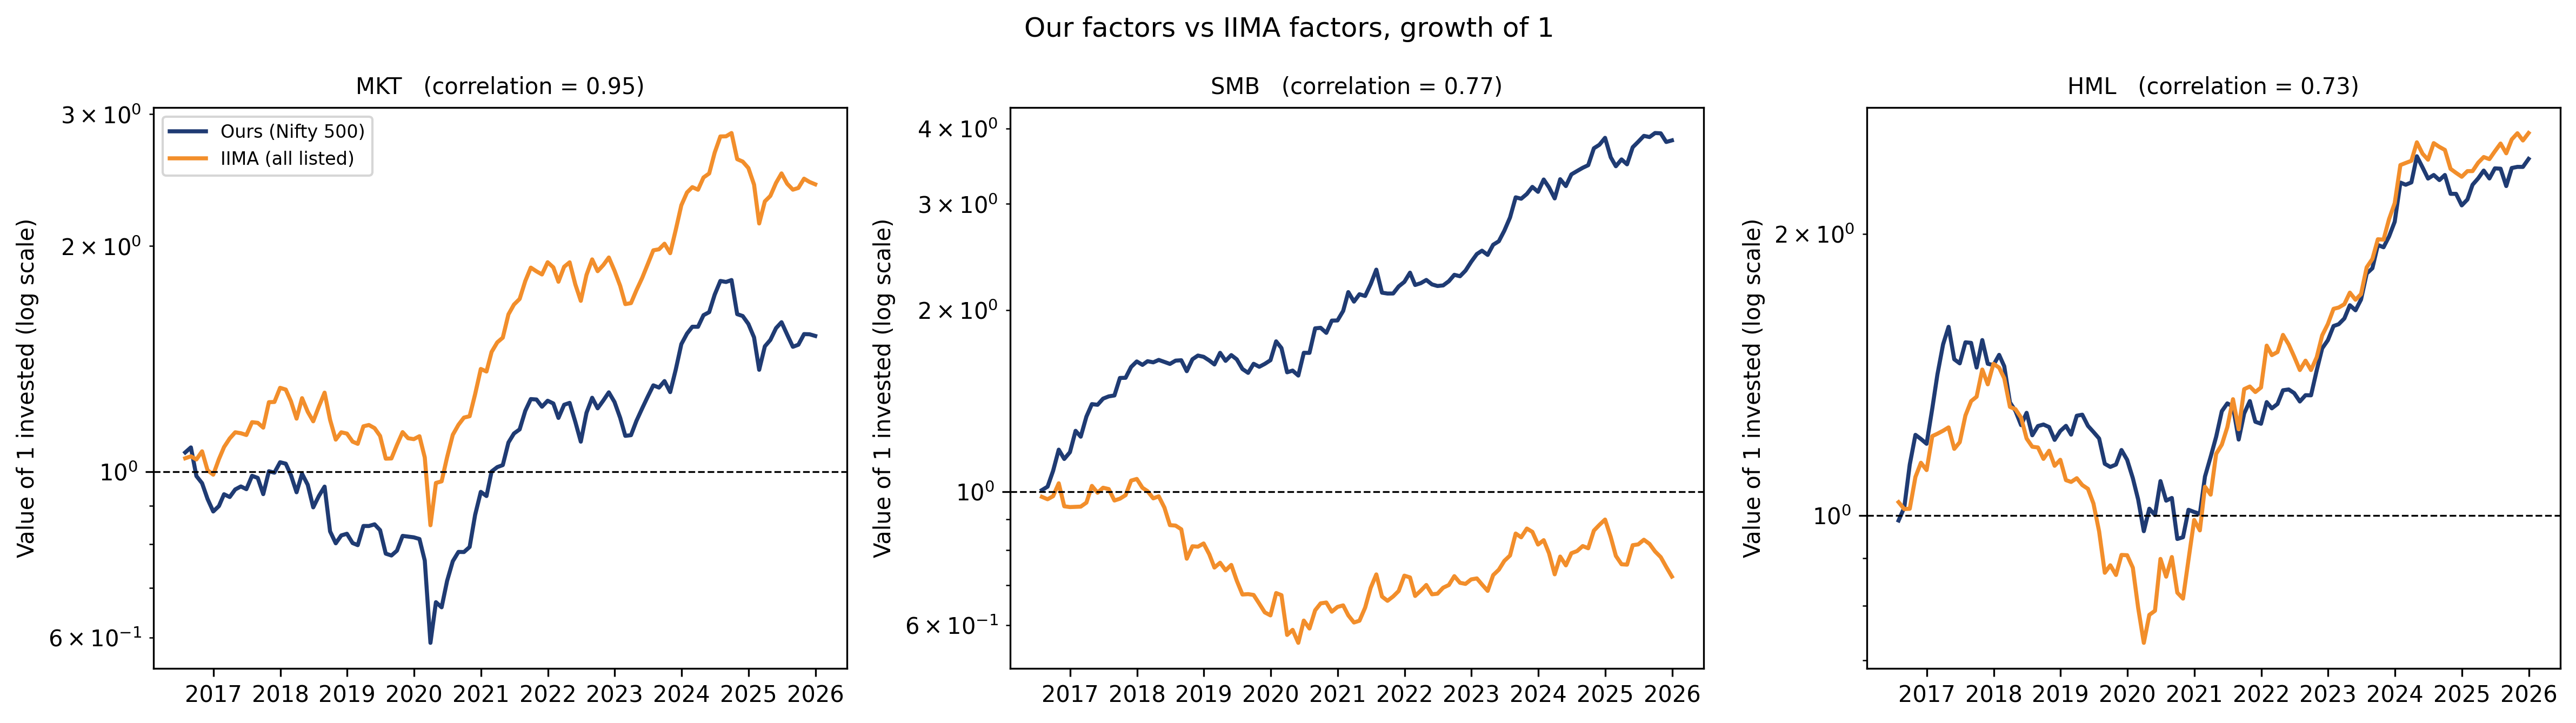

In [20]:
# 2.4 Plot - growth of 1 in each factor: ours vs IIMA (same months)

plot_cols = ["MKT", "SMB", "HML"]
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), dpi=300)

for ax, col in zip(axes, plot_cols):

    ax.plot((1 + ours[col]).cumprod(), color="#1f3b73", linewidth=1.8, label="Ours (Nifty 500)")
    ax.plot((1 + theirs[col]).cumprod(), color="#f28e2b", linewidth=1.8, label="IIMA (all listed)")

    ax.set_yscale("log")
    ax.axhline(1, color="black", linewidth=0.8, linestyle="--")
    r = validation.loc[col, "correlation"]
    ax.set_title(f"{col}   (correlation = {r:.2f})", fontsize=10)
    ax.set_ylabel("Value of 1 invested (log scale)")

axes[0].legend(loc="upper left", fontsize=8)
fig.suptitle("Our factors vs IIMA factors, growth of 1", fontsize=12)
plt.tight_layout()
plt.savefig(PLOTS_DIR / "2_4_ours_vs_iima.png", bbox_inches="tight", dpi=300)
plt.show()

In [21]:
# 2.5 Save

validation.to_csv(OUTPUT_DIR / "phase_4_external_validation.csv")
iima.to_csv(OUTPUT_DIR / "phase_4_iima_factors.csv")        # WML is used again in Step 6

print("Saved:")
print(" - phase_4_external_validation.csv")
print(" - phase_4_iima_factors.csv")

Saved:
 - phase_4_external_validation.csv
 - phase_4_iima_factors.csv


## Inferences: External validation (IIMA)

*Correlation tests construction (do the factors move together month to month?).
The mean gap tests reward (do they earn the same on average?). A factor can pass one and fail the other.*

**1. All four series pass on construction.**
Correlations: MKT 0.95, SMB 0.77, HML 0.73, Rf 0.96. Our factors capture the same risks as IIMA's, despite the different universe (Nifty 500 vs all listed stocks).

**2. HML is confirmed externally (most trustworthy factor).**
0.86% vs 0.93% a month, gap t = −0.21. The value premium holds in an independent, broader universe. Its Newey-West t is borderline (1.87, Step 1), so it is robust in level but weak in significance.

**3. SMB fails on reward: same risk, very different payoff.**
Ours +1.25% a month (t = 3.72) vs IIMA −0.20% (t = −0.50); gap 1.44% a month, t = 5.59.
- IIMA's SMB fell through the 2018–20 small-cap crash; ours stayed flat-to-rising.
- This fits survivorship bias (Step 0.8): small caps that crashed and never recovered are missing from today's Nifty 500 list.
- Part of the gap comes from the universe difference (IIMA small stocks are much smaller than ours), so this test cannot measure the two separately.
- **Our SMB premium (≈ 16% a year) should not be treated as a real Indian size premium.**

**4. MKT is lower than IIMA's, which survivorship cannot explain.**
Ours 0.49% vs IIMA 0.89% a month, gap t = −2.67. Survivorship would push our MKT up, not down. Likely causes: IIMA's broader universe (the post-2020 small/mid-cap rally), and possibly missing dividends or full-market-cap weighting in our returns. To be checked against the Nifty 500 TRI (Step 2.6).

**5. Rf matches.**
Gap 0.013% a month (0.16% a year). It is statistically significant only because Rf hardly varies; economically it is negligible.

**6. RMW and CMA cannot be validated externally** (IIMA does not publish them).

**Implication for Phase 4:** comparisons between models and variations on the same sample remain valid. Conclusions that depend on the level of SMB (the size premium, positive small-stock intercepts, "FF3 removes about 70% of CAPM pricing error") are likely overstated until the universe is rebuilt with point-in-time membership.

In [22]:
# import sys
# !{sys.executable} -m pip install BharatFinTrack

In [25]:
# 2.6a Download helper: Total Return Index (TRI) from niftyindices.com
# Calls the same backend the website uses (1 year max per request). Needs internet.

import json
import time
import requests

TRI_URLS = [                     # tried in this order until one works
    "https://niftyindices.com/Backpage.aspx/getTotalReturnIndexString",
    "https://www.niftyindices.com/Backpage.aspx/getTotalReturnIndexString",
    "https://www.niftyindices.com/Backpage/getTotalReturnIndexString",
]

TRI_HEADERS = {                  # make the request look like the website's own
    "Accept": "application/json, text/javascript, */*; q=0.01",
    "Content-Type": "application/json; charset=UTF-8",
    "X-Requested-With": "XMLHttpRequest",
    "User-Agent": "Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 "
                  "(KHTML, like Gecko) Chrome/124.0 Safari/537.36",
    "Origin": "https://niftyindices.com",
    "Referer": "https://niftyindices.com/reports/historical-data",
}

session = requests.Session()
session.get("https://niftyindices.com/reports/historical-data",
            headers={"User-Agent": TRI_HEADERS["User-Agent"]}, timeout=30)   # picks up site cookies


def download_tri(index_name, start_date, end_date):
    """
    Daily TRI for one index between two dates (format 'DD-Mon-YYYY', max 1 year apart).
    Returns a DataFrame exactly as the site sends it.
    """
    cinfo = (f"{{'name':'{index_name}','startDate':'{start_date}',"
             f"'endDate':'{end_date}','indexName':'{index_name}'}}")
    payload = {"cinfo": cinfo}

    errors = []
    for url in TRI_URLS:
        try:
            r = session.post(url, headers=TRI_HEADERS, json=payload, timeout=30)
            if r.status_code == 200:
                data = r.json()
                if isinstance(data, dict) and "d" in data:   # old site: data inside "d" as text
                    data = json.loads(data["d"])
                return pd.DataFrame(data)                    # new site: a plain list of rows
            errors.append(f"{url} -> HTTP {r.status_code}")
        except Exception as e:
            errors.append(f"{url} -> {type(e).__name__}: {e}")

    raise RuntimeError("All URLs failed:\n" + "\n".join(errors))


# Test on one month before downloading everything
test_df = download_tri("NIFTY 500", "01-Jun-2016", "30-Jun-2016")
print("Rows:", len(test_df))
print("Columns:", list(test_df.columns))
display(test_df.head(3))

Rows: 22
Columns: ['RequestNumber', 'Index Name', 'Date', 'TotalReturnsIndex', 'NTR_Value']


,RequestNumber,Index Name,Date,TotalReturnsIndex,NTR_Value
0,TRI63928977395515948300,Nifty 500,30 Jun 2016,10038.73,9969.47
1,TRI63928977395515948300,Nifty 500,29 Jun 2016,9932.52,9864
2,TRI63928977395515948300,Nifty 500,28 Jun 2016,9828.27,9760.46


In [26]:
# 2.6b Download all four indices, one year at a time (runs once; existing files are skipped)

TRI_DIR = DATA_DIR / "raw" / "external" / "nse_tri"
TRI_DIR.mkdir(parents=True, exist_ok=True)

TRI_INDICES = {                     # file name : official NSE index name
    "nifty500":    "NIFTY 500",
    "nifty100":    "NIFTY 100",
    "midcap150":   "NIFTY MIDCAP 150",
    "smallcap250": "NIFTY SMALLCAP 250",
}

TRI_START = "2016-06-01"            # June 2016, so the July 2016 return can be computed
TRI_END = pd.Timestamp("2026-06-30")

year_starts = pd.date_range(TRI_START, TRI_END, freq="12MS")    # 1 Jun of each year

for short_name, index_name in TRI_INDICES.items():

    out_file = TRI_DIR / f"{short_name}.csv"
    if out_file.exists():
        print(short_name, "-> already downloaded, skipped")
        continue

    pieces = []
    for start in year_starts:
        end = min(start + pd.DateOffset(years=1) - pd.Timedelta(days=1), TRI_END)
        pieces.append(download_tri(index_name,
                                   start.strftime("%d-%b-%Y"),
                                   end.strftime("%d-%b-%Y")))
        time.sleep(1)               # small pause between requests

    tri = pd.concat(pieces, ignore_index=True).drop_duplicates()
    tri.to_csv(out_file, index=False)
    print(short_name, "-> rows:", len(tri))

nifty500 -> rows: 2497
nifty100 -> rows: 2497
midcap150 -> rows: 2497
smallcap250 -> rows: 2497


### Step 2.6: Index checks (same universe, no survivorship bias)

NSE indices are rebuilt from their actual members at each point in time, so their returns are free of survivorship bias. They also cover the same Nifty 500 universe, so they test our factors more directly than IIMA does.

1. **MKT check:** our market return (MKT + Rf) vs the Nifty 500 Total Return Index. They should be close. Remaining differences come from weighting (we use full market cap, NSE uses free-float) and from how stock returns were built in Phase 1 (e.g. dividends).
2. **SMB check:** our SMB vs small-minus-large index spreads (Smallcap 250, Midcap 150 and their average, each minus Nifty 100). The spreads are survivorship-free. If our SMB is much higher than the spreads, the excess comes mostly from survivorship bias.

*Caveat:* the index spreads are not value-neutral the way SMB is (SMB averages across B/M groups), and they use free-float weights. So we compare averages and correlations, and do not expect an exact match.

In [30]:
# 2.6c Daily TRI -> month-end values -> monthly returns

def load_tri_monthly(file_path):
    """Read one downloaded TRI file and return monthly returns (month-end dates)."""
    df = pd.read_csv(file_path)

    # Find the date column and the gross Total Return Index column by name
    date_col = [c for c in df.columns if "date" in c.lower()][0]
    tri_col = [c for c in df.columns
               if ("total" in c.lower() or "tri" in c.lower())
               and "net" not in c.lower() and "ntr" not in c.lower()
               and "date" not in c.lower()][0]

    df["date"] = pd.to_datetime(df[date_col], format="mixed", dayfirst=True)   # dates mix "June" and "Apr"
    df["tri"] = pd.to_numeric(df[tri_col].astype(str).str.replace(",", ""), errors="coerce")

    df = df.dropna(subset=["tri"]).sort_values("date")
    month_end = df.set_index("date")["tri"].resample(pd.offsets.MonthEnd()).last()   # last trading day of each month

    print(f"{file_path.name:16s} date column: '{date_col}' | TRI column: '{tri_col}' | "
          f"{month_end.index.min().date()} to {month_end.index.max().date()}")
    return month_end.pct_change()


tri_monthly = pd.DataFrame({
    short_name: load_tri_monthly(TRI_DIR / f"{short_name}.csv")
    for short_name in TRI_INDICES
})

# Keep the 120 months of our factors
tri_monthly = tri_monthly.loc[df_factors.index]

print("\nMonths:", len(tri_monthly))                              # expect 120
print("Missing values:", tri_monthly.isna().sum().to_dict())      # must be all 0
display(tri_monthly.describe().round(4))

nifty500.csv     date column: 'Date' | TRI column: 'TotalReturnsIndex' | 2016-06-30 to 2026-06-30
nifty100.csv     date column: 'Date' | TRI column: 'TotalReturnsIndex' | 2016-06-30 to 2026-06-30
midcap150.csv    date column: 'Date' | TRI column: 'TotalReturnsIndex' | 2016-06-30 to 2026-06-30
smallcap250.csv  date column: 'Date' | TRI column: 'TotalReturnsIndex' | 2016-06-30 to 2026-06-30

Months: 120
Missing values: {'nifty500': 0, 'nifty100': 0, 'midcap150': 0, 'smallcap250': 0}


,nifty500,nifty100,midcap150,smallcap250
count,120.0000,120.0000,120.0000,120.0000
mean,0.0121,0.0112,0.0158,0.0145
std,0.0490,0.0472,0.0582,0.0690
min,-0.2403,-0.2264,-0.2823,-0.3342
25%,-0.0136,-0.0131,-0.0144,-0.0206
50%,0.0127,0.0117,0.0197,0.0141
75%,0.0408,0.0382,0.0526,0.0584
max,0.1453,0.1462,0.1491,0.1710


In [31]:
# 2.6d MKT check: our market return vs Nifty 500 TRI (same universe, no survivorship)
# Our market return = MKT + Rf

mkt_check = pd.DataFrame({
    "ours": df_factors["MKT"] + df_factors["Rf"],
    "nifty500_tri": tri_monthly["nifty500"],
})
mkt_gap = factor_premia((mkt_check["ours"] - mkt_check["nifty500_tri"]).to_frame("gap"))

n_years = len(mkt_check) / 12
cagr = (1 + mkt_check).prod() ** (1 / n_years) - 1                  # compound annual return

print("Correlation:", round(mkt_check.corr().iloc[0, 1], 3))
print("CAGR ours:          ", round(cagr["ours"] * 100, 2), "%")
print("CAGR Nifty 500 TRI: ", round(cagr["nifty500_tri"] * 100, 2), "%")
print("Monthly gap (ours - index):", round(mkt_gap.loc["gap", "mean_monthly_%"], 3),
      "% | NW t =", round(mkt_gap.loc["gap", "t_stat_nw"], 2))
print("Tracking error (annual):",
      round((mkt_check["ours"] - mkt_check["nifty500_tri"]).std() * np.sqrt(12) * 100, 2), "%")

Correlation: 0.965
CAGR ours:           9.82 %
CAGR Nifty 500 TRI:  13.9 %
Monthly gap (ours - index): -0.299 % | NW t = -1.93
Tracking error (annual): 4.61 %


In [32]:
# 2.6e SMB check: our SMB vs small-minus-large index spreads (no survivorship)

spreads = pd.DataFrame({
    "SMB_ours": df_factors["SMB"],
    "Small250 - Nifty100": tri_monthly["smallcap250"] - tri_monthly["nifty100"],
    "Mid150 - Nifty100": tri_monthly["midcap150"] - tri_monthly["nifty100"],
    "MidSmall - Nifty100": (tri_monthly["midcap150"] + tri_monthly["smallcap250"]) / 2
                           - tri_monthly["nifty100"],          # closest to our small half
})

smb_check = factor_premia(spreads)[["mean_monthly_%", "t_stat", "t_stat_nw", "mean_annual_%"]]
smb_check["corr_with_SMB_ours"] = spreads.corr()["SMB_ours"]

# Gap between our SMB and each spread, with its Newey-West t-stat
for col in spreads.columns[1:]:
    gap = factor_premia((spreads["SMB_ours"] - spreads[col]).to_frame("gap")).loc["gap"]
    smb_check.loc[col, "gap_vs_SMB_%"] = gap["mean_monthly_%"]
    smb_check.loc[col, "gap_t_nw"] = gap["t_stat_nw"]

display(smb_check.round(3))

,mean_monthly_%,t_stat,t_stat_nw,mean_annual_%,corr_with_SMB_ours,gap_vs_SMB_%,gap_t_nw
factor,,,,,,,
SMB_ours,1.298,4.021,4.466,15.580,1.000,NaN,NaN
Small250 - Nifty100,0.331,0.903,0.852,3.971,0.839,0.967,3.899
Mid150 - Nifty100,0.460,1.874,2.045,5.521,0.730,0.838,4.266
MidSmall - Nifty100,0.395,1.330,1.309,4.746,0.818,0.903,4.473


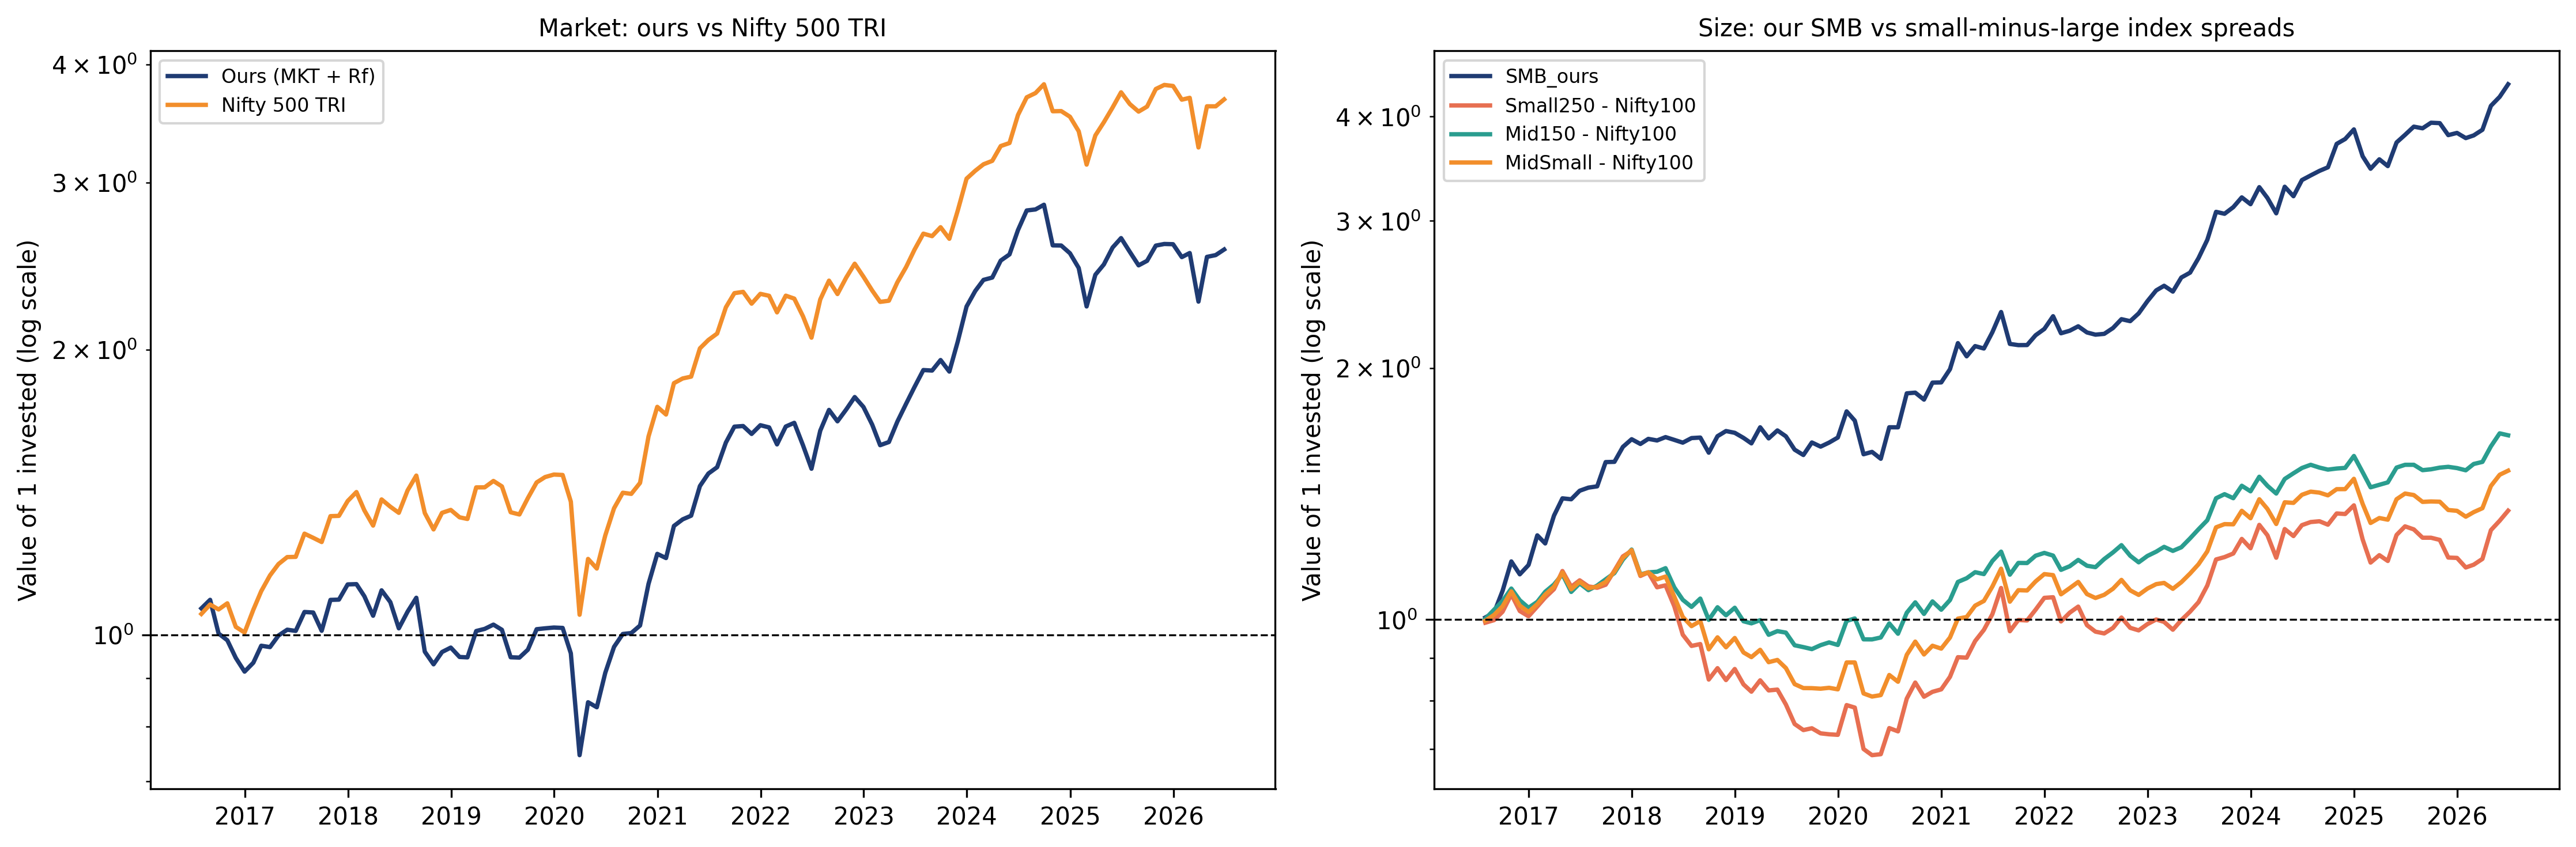

In [33]:
# 2.6f Plot - growth of 1: market and size checks

fig, axes = plt.subplots(1, 2, figsize=(15, 5), dpi=300)

# Left: our market vs Nifty 500 TRI
axes[0].plot((1 + mkt_check["ours"]).cumprod(), color="#1f3b73", linewidth=1.8, label="Ours (MKT + Rf)")
axes[0].plot((1 + mkt_check["nifty500_tri"]).cumprod(), color="#f28e2b", linewidth=1.8, label="Nifty 500 TRI")
axes[0].set_title("Market: ours vs Nifty 500 TRI", fontsize=10)

# Right: our SMB vs index spreads
spread_colors = {"SMB_ours": "#1f3b73", "Small250 - Nifty100": "#e76f51",
                 "Mid150 - Nifty100": "#2a9d8f", "MidSmall - Nifty100": "#f28e2b"}
for col, color in spread_colors.items():
    axes[1].plot((1 + spreads[col]).cumprod(), color=color, linewidth=1.8, label=col)
axes[1].set_title("Size: our SMB vs small-minus-large index spreads", fontsize=10)

for ax in axes:
    ax.set_yscale("log")
    ax.axhline(1, color="black", linewidth=0.8, linestyle="--")
    ax.set_ylabel("Value of 1 invested (log scale)")
    ax.legend(fontsize=8, loc="upper left")

plt.tight_layout()
plt.savefig(PLOTS_DIR / "2_6_index_checks.png", bbox_inches="tight", dpi=300)
plt.show()

In [34]:
# 2.6g Save

tri_monthly.to_csv(OUTPUT_DIR / "phase_4_nse_tri_monthly.csv")
smb_check.to_csv(OUTPUT_DIR / "phase_4_smb_index_check.csv")

print("Saved:")
print(" - phase_4_nse_tri_monthly.csv")
print(" - phase_4_smb_index_check.csv")

Saved:
 - phase_4_nse_tri_monthly.csv
 - phase_4_smb_index_check.csv


In [35]:
# 2.6h Which stocks dominate our market factor? (June weights, full market cap)
# Indicative only: MKT uses monthly weights, this uses the June snapshot

for year in [2016, 2020]:
    snap = formation_df[formation_df["formation_date"].dt.year == year].copy()
    snap["weight_%"] = snap["me_june"] / snap["me_june"].sum() * 100
    top10 = snap.nlargest(10, "weight_%")

    print(f"\nJune {year}: {len(snap)} stocks | top 10 = {top10['weight_%'].sum():.1f}% of the market")
    display(top10[["symbol", "industry", "weight_%"]].round(2))

# A large stock that merged away (into HDFC Bank, 2023): is it in the sample?
print("HDFC Ltd ('HDFC') in sample:", "HDFC" in set(formation_df["symbol"]))


June 2016: 293 stocks | top 10 = 31.8% of the market


,symbol,industry,weight_%
207,BAJFINANCE,Financial Services,4.71
52,JSWSTEEL,Metals & Mining,3.80
124,RELIANCE,Oil Gas & Consumable Fuels,3.38
236,HDFCBANK,Financial Services,3.20
222,ITC,Fast Moving Consumer Goods,3.19
170,BEL,Capital Goods,3.04
33,ONGC,Oil Gas & Consumable Fuels,2.98
247,INFY,Information Technology,2.87
259,GRASIM,Construction Materials,2.34
244,IOC,Oil Gas & Consumable Fuels,2.30



June 2020: 373 stocks | top 10 = 36.8% of the market


,symbol,industry,weight_%
1419,RELIANCE,Oil Gas & Consumable Fuels,9.29
1378,TCS,Information Technology,6.30
1558,HDFCBANK,Financial Services,4.71
1550,HINDUNILVR,Fast Moving Consumer Goods,4.13
1579,INFY,Information Technology,2.52
1469,BHARTIARTL,Telecommunication,2.46
1331,KOTAKBANK,Financial Services,2.17
1456,ITC,Fast Moving Consumer Goods,1.93
1545,ICICIBANK,Financial Services,1.83
1345,MARUTI,Automobile and Auto Components,1.42


HDFC Ltd ('HDFC') in sample: False


## Inferences: Index checks (Nifty indices, no survivorship bias)

> *Note: point 1's list of causes is superseded by the data-quality findings below (2.6h–2.6j): wrong ME levels and uncorrected corporate-action returns also lower our MKT.*

**1. Our market return trails the Nifty 500 TRI by about 4% a year.**
CAGR 9.8% vs 13.9%; correlation 0.965; tracking error 4.6% a year; monthly gap −0.30% (NW t = −1.93).
- The gap opens in 2016–20 (including a deeper Covid crash); from 2021 the two move in parallel and ours gains faster in 2023–24.
- Likely causes: (a) full market-cap weights, the classical FF rule, which in India overweight promoter-heavy PSUs and MNC subsidiaries; (b) large stocks missing from today's list (e.g. HDFC Ltd, merged in 2023); (c) possibly missing dividends in Phase 1 returns.
- Survivorship bias cannot explain this gap; it would push our market return up.

**2. Survivorship bias is confirmed as the main source of our SMB.**
- Our SMB earns 15.6% a year; survivorship-free index spreads earn 4.0–5.5% a year. The gap is 0.84–0.97% a month (NW t = 3.9–4.5).
- Correlations are high (0.73–0.84): our SMB captures the right risk, but about 70% of its premium is not real.
- The index spreads fell 30–40% in the 2018–20 small-cap crash; our SMB did not. The small caps that crashed are missing from today's list.
- The survivorship-free size premium in the Nifty 500 is about 4–5% a year and not significant (t = 0.85–2.05).

**3. Consequences for Phase 3 results.**
- The SMB premium, the positive small-stock intercepts and the large CAPM pricing errors for small portfolios are overstated.
- Model rankings (FF5 ≈ FF3, CAPM rejected) and the HML result are less affected, but every number is conditional on a survivor-only sample.

**Verdict, Step 2:** construction Pass (all correlations ≥ 0.73); reward: HML Pass, MKT Fragile, **SMB Fail (survivorship bias)**.

In [36]:
# 2.6i Check market equity (ME) against returns, month by month
# If ME is right: ME_t / ME_(t-1) is close to 1 + return
# A split or bonus with a wrong share count shows up as a big jump in ME but not in return

chk = panel_df[["symbol", "date", "ret", "me", "me_lag"]].copy()

# Count missing values first: split months set to NaN would otherwise be hidden
print("Missing ret:", chk["ret"].isna().sum(),
      "| missing me:", chk["me"].isna().sum(),
      "| missing me_lag:", chk["me_lag"].isna().sum())
chk = chk.dropna()

chk = chk[(chk["me_lag"] > 0) & (chk["me"] > 0)]

chk["me_growth"] = chk["me"] / chk["me_lag"]
chk["mismatch"] = chk["me_growth"] / (1 + chk["ret"])     # close to 1 if ME and return agree

bad = chk[(chk["mismatch"] > 1.5) | (chk["mismatch"] < 1 / 1.5)]

print("Stock-months checked:", len(chk))
print("Stock-months where ME and return disagree by > 50%:", len(bad),
      "| stocks affected:", bad["symbol"].nunique())
display(bad.sort_values("mismatch").head(20).round(3))

# When do the mismatches happen? (wrong share counts would cluster before ~2020)
print(bad.groupby(bad["date"].dt.year).size())

# Spot check: is TCS in the June 2016 sample at all?
snap16 = formation_df[formation_df["formation_date"].dt.year == 2016]
print("\nTCS in June 2016 sample:", "TCS" in set(snap16["symbol"]))
if "TCS" in set(snap16["symbol"]):
    print("TCS June 2016 weight %:",
          round(snap16.loc[snap16["symbol"] == "TCS", "me_june"].iloc[0] / snap16["me_june"].sum() * 100, 2))

Stock-months checked: 45691
Stock-months where ME and return disagree by > 50%: 94 | stocks affected: 78


,symbol,date,ret,me,me_lag,me_growth,mismatch
31237,IIFL,2019-06-30,-0.104,4541.103,13326.423,0.341,0.380
24758,GODREJCP,2016-08-31,-0.046,51658.953,108365.612,0.477,0.500
60751,TCS,2017-07-31,0.058,477002.794,886443.467,0.538,0.509
3771,ANANTRAJ,2020-10-31,0.108,535.503,914.798,0.585,0.528
3904,ANGELONE,2026-02-28,-0.082,11659.541,23091.783,0.505,0.550
36307,JSWENERGY,2023-01-31,-0.171,39153.516,85801.721,0.456,0.551
48155,OIL,2024-07-31,-0.201,93963.922,78408.264,1.198,1.500
30455,IDEA,2023-02-28,-0.035,33019.474,22705.018,1.454,1.508
30481,IDEA,2025-04-30,0.047,77236.690,48615.174,1.589,1.517
50900,PNBHOUSING,2023-05-31,0.133,13113.461,7612.539,1.723,1.520


date
2016     1
2017     6
2018    13
2019     8
2020     8
2021     8
2022     9
2023    11
2024    14
2025    12
2026     4
dtype: int64

TCS in June 2016 sample: False


In [37]:
# 2.6j Three follow-up checks on market equity (ME)

# 1. Return error or ME error?
#    Big |return| with smooth ME -> the return is wrong (uncorrected bonus/split)
#    Normal return with ME jump  -> ME is wrong, or shares really changed (rights, merger, QIP)
bad = bad.copy()
bad["likely_problem"] = np.where(bad["ret"].abs() > 0.25, "check return", "check ME")
print(bad["likely_problem"].value_counts())
display(bad[bad["likely_problem"] == "check return"].sort_values("ret").round(3))

# 2. June 2016 level check: our ME (Rs crore) for the 2016 top 10
#    Compare with the actual market cap in June 2016 (from screener.in, moneycontrol, or NSE)
top16 = (formation_df[formation_df["formation_date"].dt.year == 2016]
         .nlargest(10, "me_june")[["symbol", "me_june"]])
print("\nTotal June 2016 ME of sample (Rs crore):",
      round(formation_df.loc[formation_df["formation_date"].dt.year == 2016, "me_june"].sum()))
display(top16.round(0))

# 3. Why is TCS missing in June 2016?
print("\nTCS formation years in sample:",
      formation_df.loc[formation_df["symbol"] == "TCS", "formation_date"].dt.year.tolist())
tcs_cols = ["symbol", "fy_end", "formation_date", "me_formation", "book_value",
            "check_me", "months_traded", "trade_days_12m", "available_date"]
display(char_df.loc[char_df["symbol"] == "TCS", tcs_cols].head(4))

likely_problem
check ME        84
check return    10
Name: count, dtype: int64


,symbol,date,ret,me,me_lag,me_growth,mismatch,likely_problem
7622,BAJFINANCE,2025-06-30,-0.898,320259.907,570012.662,0.562,5.508,check return
47568,NYKAA,2022-11-30,-0.851,49075.866,54703.982,0.897,6.002,check return
2974,AIIL,2026-01-31,-0.839,42937.350,54405.603,0.789,4.895,check return
36712,JUBLFOOD,2022-04-30,-0.793,36027.537,37216.307,0.968,4.675,check return
65721,VBL,2024-09-30,-0.596,196963.833,195034.448,1.010,2.500,check return
65706,VBL,2023-06-30,-0.526,79927.359,110064.358,0.726,1.533,check return
53435,RELIANCE,2017-09-30,-0.510,448858.201,475943.116,0.943,1.926,check return
23387,GICRE,2018-07-31,-0.496,62549.565,64281.095,0.973,1.930,check return
8406,BANKINDIA,2019-03-31,0.255,28112.472,14496.712,1.939,1.546,check return
3906,ANGELONE,2026-04-30,0.357,28119.135,11376.053,2.472,1.822,check return



Total June 2016 ME of sample (Rs crore): 9310392


,symbol,me_june
207,BAJFINANCE,438576.0
52,JSWSTEEL,353698.0
124,RELIANCE,314241.0
236,HDFCBANK,298041.0
222,ITC,296684.0
170,BEL,282867.0
33,ONGC,277582.0
247,INFY,267603.0
259,GRASIM,218143.0
244,IOC,214049.0



TCS formation years in sample: [2017, 2019, 2020, 2021, 2022, 2023, 2024, 2025]


,symbol,fy_end,formation_date,me_formation,book_value,check_me,months_traded,trade_days_12m,available_date
164,TCS,31-03-2015,30-06-2015,502646.8286,50635.0,False,54.0,244.0,30-06-2015
565,TCS,31-03-2016,30-06-2016,NaN,71072.0,False,66.0,248.0,30-06-2016
985,TCS,31-03-2017,30-06-2017,886443.4666,86214.0,False,78.0,247.0,30-06-2017
1411,TCS,31-03-2018,30-06-2018,NaN,85128.0,False,90.0,249.0,30-06-2018


## Inferences: Data-quality checks (Steps 2.6h–2.6j)

**1. Market equity (ME) is overstated before some splits and bonuses.**
June 2016 ME vs actual market cap (approx.): BAJFINANCE ~9×, JSWSTEEL ~9×, BEL ~10×, GRASIM ~5×, ONGC ~1.5×; RELIANCE, HDFCBANK, ITC, INFY about right. The overstatement matches each stock's next split or bonus factor: the share count after the split is used with the price before it. This explains the implausible June 2016 top 10 (Bajaj Finance as the largest stock).

**2. At least 8 corporate actions were not corrected in returns.**
Fake crashes from −50% to −90%: BAJFINANCE Jun-2025, NYKAA Nov-2022, AIIL Jan-2026, JUBLFOOD Apr-2022, VBL Jun-2023 and Sep-2024, RELIANCE Sep-2017, GICRE Jul-2018. RELIANCE Sep-2017 alone lowers MKT by about 4 percentage points in that month.

**3. Large stocks are missing in some years because ME is missing.**
TCS has no June ME in 2016 and 2018 and is dropped from both formation years; its June 2017 ME is about 2× too high (1:1 bonus in 2018).

**4. Together with survivorship bias (Step 2.6), Phase 1 has four data problems:**
survivor-only universe, wrong ME levels, uncorrected corporate-action returns, and missing ME for large stocks. They distort value weights, size breakpoints, B/M sorts and every factor.

**Decision:** Phase 4 is paused after Step 2. Phase 1 will be rebuilt (point-in-time universe, consistent ME and returns), Phases 2–3 rerun, and Steps 0–2 of Phase 4 reused as the acceptance test for the new data.